# Qiskit-Metal-to-Litho 12-qubit flux-tunable Xmon processor: a Quantcore-PDK rebuild, step by step

**Source:** Onri Jay Benally (OJB-Quantum), **Qiskit-Metal-to-Litho**, `12_Qubit_Flux_Tunable_Processor_in_Colab.ipynb`,
<https://github.com/OJB-Quantum/Qiskit-Metal-to-Litho>, licence **CC BY 4.0** (`LICENSE`; the notebook says "Open
Access (CC-BY-4.0)"; attribution: © Onri Jay Benally 2026, adapted). The notebook's design constants were read on
2026-11-03 (never executed); the repository now keeps it as `Python Code_Qiskit Metal_Designs/12_Flux_Tunable_Xmons_Colab.ipynb`,
whose GDS export cell was read on 2026-11-18 (the cheese row below). Spec: `docs/designs/community/qm2litho_12q_flux_processor.md`.

**What the chip is:** twelve flux-tunable Metal `TransmonCrossFL` Xmons in two columns of six (rows 1260 µm apart),
one column on each side of a straight vertical feedline (11.7/5.1 µm) between two launch pads. Each qubit has a claw
toward the line, a λ/4 meander readout multiplexed 6.05–6.82 GHz (70 MHz steps, L = v/(4f), v = 1.2 × 10⁸ m/s) and a
flux line fanned out to its own side pad. There are no qubit–qubit couplers: it is a readout and flux test processor.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (Qiskit-Metal-to-Litho) | this rebuild |
|---|---|---|
| die and frame | Metal's 11 × 11 mm chip centred on (0, 0), no frame | PDK frame on the same 11 × 11 mm die (Designer = source + (5500, 5500) µm), device ID `QM2L-12Q` |
| stack | silicon (Metal default) | PDK sapphire 650 µm, εr 10.25 |
| qubits | Metal `TransmonCrossFL` (cross 260/35/20 µm, flux T-line, claw 190 × 10 µm) | the same cell and options through the `metal:` wrapper |
| junction | lumped L_J 15.904 nH, a flux-tunable SQUID in the circuit | a **Quantcore trilayer SQUID** drawn for L_J = 15.904 nH (`trilayer_junction(..., squid=True)`); R_n is flagged, not retuned |
| readout coupler | 3-tooth, 260 µm interdigital fingers 18 µm from the feedline | a qcc λ/4 hanger: 260 µm coupled section, 7 µm ground strip (the spec's reading of the 18 µm gap), shorted |
| launch and flux pads | `BondPad`-like pads 590–660 µm inside the chip edge | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm from the die edge (north/south launch pads, west/east flux pads) |
| cheese | **yes**: the notebook exports its GDS with Metal's `QGDSRenderer`, native cheesing on (25 µm squares every 100 µm, 25 µm buffer, 200 µm chip-edge margin) | **the original's**: Metal's rule drawn by the build (`cheese` = `metal_cheese_rule()`), no PDK band |
| netlist, LOM, FEM jobs | none | our netlist, LOM, and Q3D / eigenmode job exports per qubit |

**Simplified:** the meander is KQC's (5 turns, ≈ ±300 µm, the source's amplitude); PHIDL's Euler-smoothed centrelines
are not reproduced. The flux lines run at 6/8 µm all the way (no 95 µm taper to 5/3 µm at the qubit; the Metal flux
pin itself is 5/3 µm).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die with Metal's cheese rule, the two launch pads and the twelve flux pads, the feedline,
the twelve flux-tunable Xmons with their trilayer SQUIDs, their λ/4 hanger readouts, the twelve flux lines, and then
the whole chip (the targets and sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `qm2litho_12q_flux_processor.v1.ipynb`; both save the same
`qm2litho_12q_flux_processor.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the
cheese by the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, the design warnings by the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline is drawn as soon as the
launch pads exist (segment 3), each readout once its qubit is there (segment 5) and each flux line once both its qubit
and its pad are (segment 7). Every position is a source coordinate + (5500, 5500) µm, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 11 × 11 mm die with the PDK frame and Metal's GDS cheese rule (the original's) |
| 2 | the two launch pads (north / south) and the twelve flux pads (west / east), on the PDK pad rule |
| 3 | the readout line: the straight 11.7/5.1 µm feedline between the launch pads |
| 4 | the twelve `TransmonCrossFL` Xmons (two columns of six) with their trilayer SQUIDs |
| 5 | the twelve λ/4 hanger readouts, 6.05 … 6.82 GHz in 70 MHz steps |
| 6 | the coupling: none (a readout and flux test processor: no qubit–qubit coupler) |
| 7 | the control routing: twelve flux lines, each from its qubit's flux T-line to its side pad |
| 8 | the whole chip: the targets and sim groups, the centring, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The source's 11 × 11 mm chip is kept (the PDK frame fits any die size),
so Designer = source + (5500, 5500) µm. The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3 alignment
grids (1001/0), the chip boundary (100/0) and the device ID (`name_chip`) on a free edge. 
**Cheese: the original's.** The source exports its GDS with Metal's `QGDSRenderer` and its native cheesing on
("Native Cheesing and GDS Export": `cheese.view_in_file` on for the metal layer, the renderer's default hole
size, pitch, buffer and edge margin), so the original has cheese and it wins over the PDK band:
`chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule (25 µm squares every 100 µm, 25 µm clear of the
3/0 keep-outs, none within 200 µm of the die edge), and the build draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


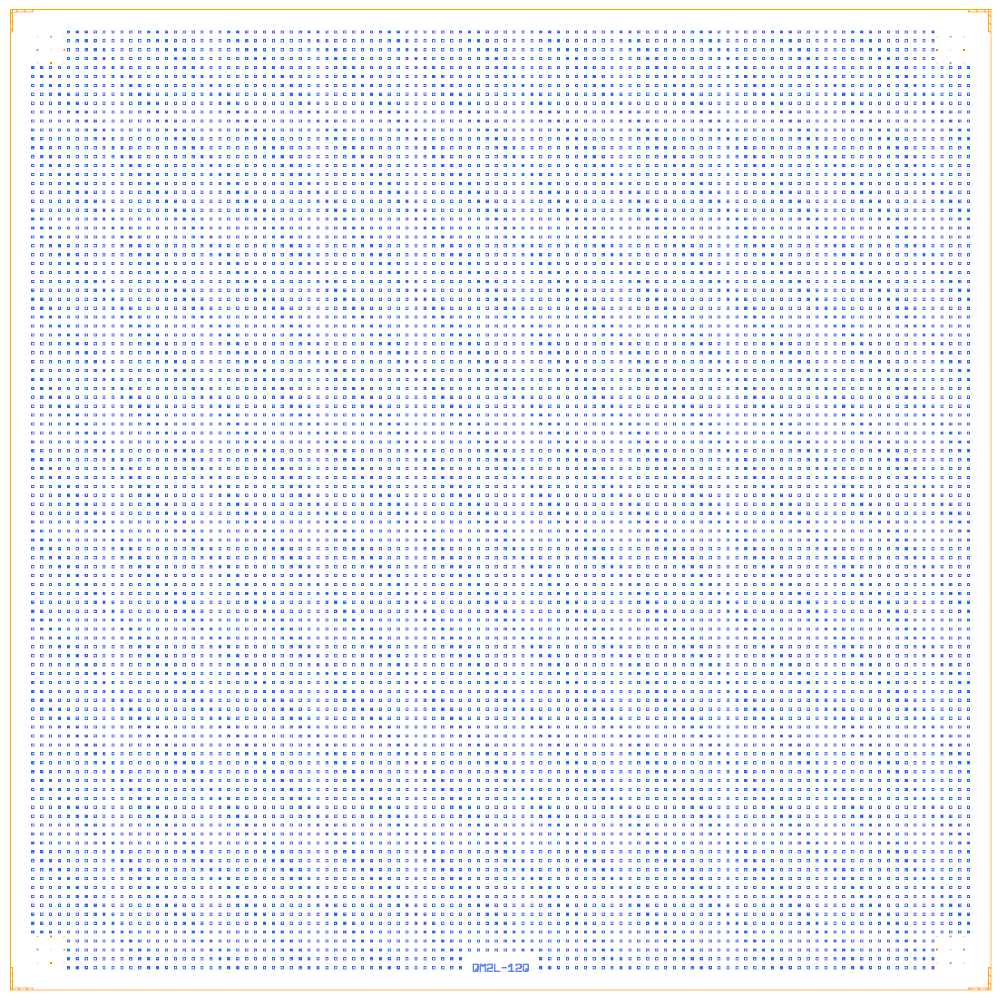

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_die.png')

In [5]:
X0, Y0 = 5500, 5500                              # Metal's 11 × 11 mm chip is centred on (0, 0)
d = Designer("qm2litho_12q_flux_processor", box=(0, 0, 11000, 11000), chip={"name_chip": "QM2L-12Q", "cheese": metal_cheese_rule()},
             live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "qm2litho_12q_flux_processor_die.png", size=(1000, 1000), width=360)

## Design 2 · Bond pads: launch pads, flux pads and the PDK pad rule

The source's launch pads (260 × 320 µm, 260 µm taper, 60 µm clearance, for the 11.7/5.1 µm feedline) sit at y = ±4200 µm
and its twelve flux pads (150 × 260 µm, 220 µm taper, 42 µm clearance, 6/8 µm lead) have their outer edge at
x = ±4850 µm: 590–660 µm inside the chip edge. The PDK puts every bond pad with the outer edge of its etch **`frame.pad_edge` =
100 µm from the die edge**, whatever the source did. `edge="n"` / `"s"` / `"w"` / `"e"` slides a pad perpendicular to that edge
until it holds and keeps its position along the edge, so every flux pad stays at its qubit's row.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_TOP | `BondPad` | n | 100.0 | ✓ |
| P_BOT | `BondPad` | s | 100.0 | ✓ |
| F_Q01_L | `BondPad` | w | 100.0 | ✓ |
| F_Q01_R | `BondPad` | e | 100.0 | ✓ |
| F_Q02_L | `BondPad` | w | 100.0 | ✓ |
| F_Q02_R | `BondPad` | e | 100.0 | ✓ |
| F_Q03_L | `BondPad` | w | 100.0 | ✓ |
| F_Q03_R | `BondPad` | e | 100.0 | ✓ |
| F_Q04_L | `BondPad` | w | 100.0 | ✓ |
| F_Q04_R | `BondPad` | e | 100.0 | ✓ |
| F_Q05_L | `BondPad` | w | 100.0 | ✓ |
| F_Q05_R | `BondPad` | e | 100.0 | ✓ |
| F_Q06_L | `BondPad` | w | 100.0 | ✓ |
| F_Q06_R | `BondPad` | e | 100.0 | ✓ |

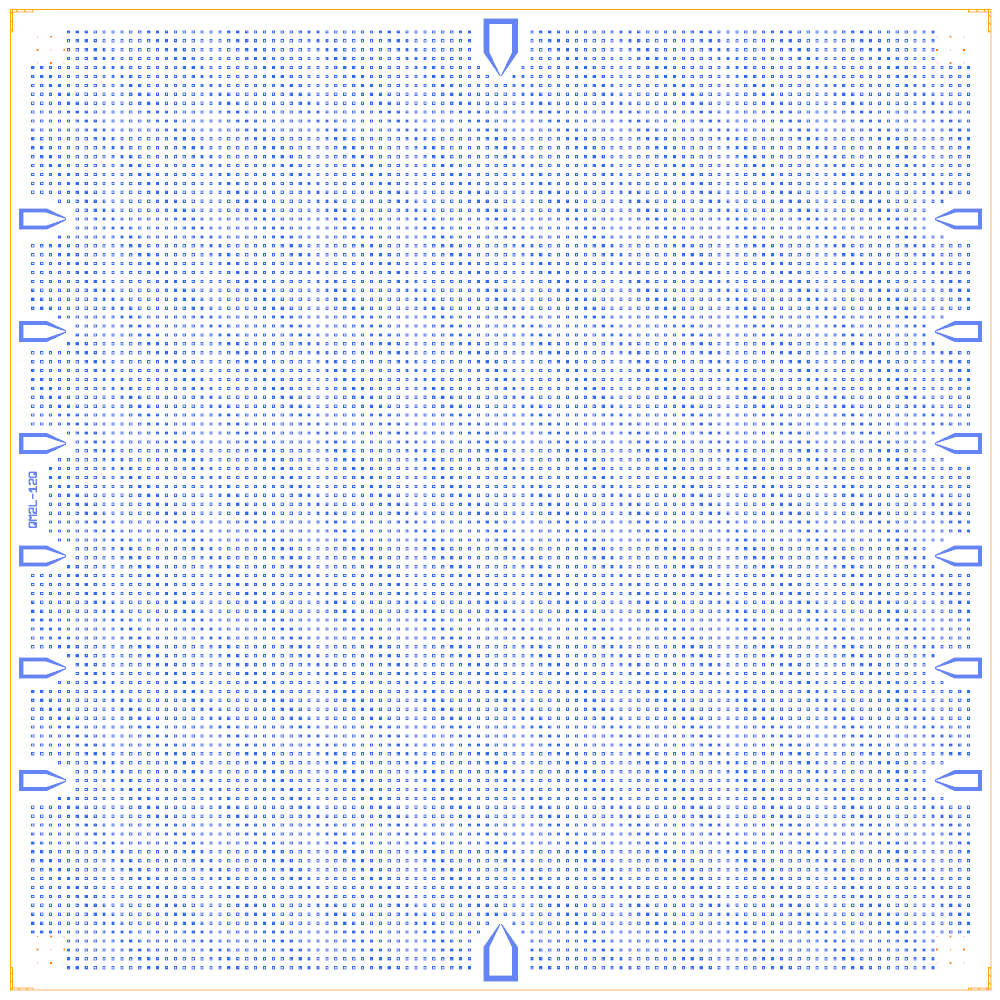

**On the chip so far:** 14 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 14 component(s) `P_TOP`, `P_BOT`, `F_Q01_L`, `F_Q01_R`, `F_Q02_L`, `F_Q02_R`, `F_Q03_L`, `F_Q03_R` … (+6).

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_s2_pads.png')

In [6]:
LAUNCH = dict(pad_width=260, pad_height=320, taper_length=260, pad_gap=60, a=11.7, b=5.1)
FLUXPAD = dict(pad_width=150, pad_height=260, taper_length=220, pad_gap=42, a=6, b=8)
ROWS = (3150, 1890, 630, -630, -1890, -3150)     # source qubit rows (µm)
SITES = [(f"Q{row:02d}_{side}", x, y) for row, y in enumerate(ROWS, start=1) for side, x in (("L", -2350), ("R", 2350))]
with d.batch():
    top = d.add("P_TOP", "BondPad", at=(X0, Y0 + 4200), rot=180, edge="n", **LAUNCH)
    bot = d.add("P_BOT", "BondPad", at=(X0, Y0 - 4200), rot=0, edge="s", **LAUNCH)
    for name, x, y in SITES:
        left = x < 0
        d.add(f"F_{name}", "BondPad", at=(X0 + (-1 if left else 1) * (4850 - 260 - 220), Y0 + y),
              rot=270 if left else 90, edge="w" if left else "e", **FLUXPAD)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "qm2litho_12q_flux_processor_s2_pads.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the feedline

**The feedline** is a straight 11.7/5.1 µm CPW from the top launch pad's port `a` to the bottom one's, with 70 µm bends.
It travels −y, so its "right" side is the west column and its "left" side the east column. It needs no qubit, so it comes first; every
readout will hang on it (Design 5).

FL: 9520.0 µm


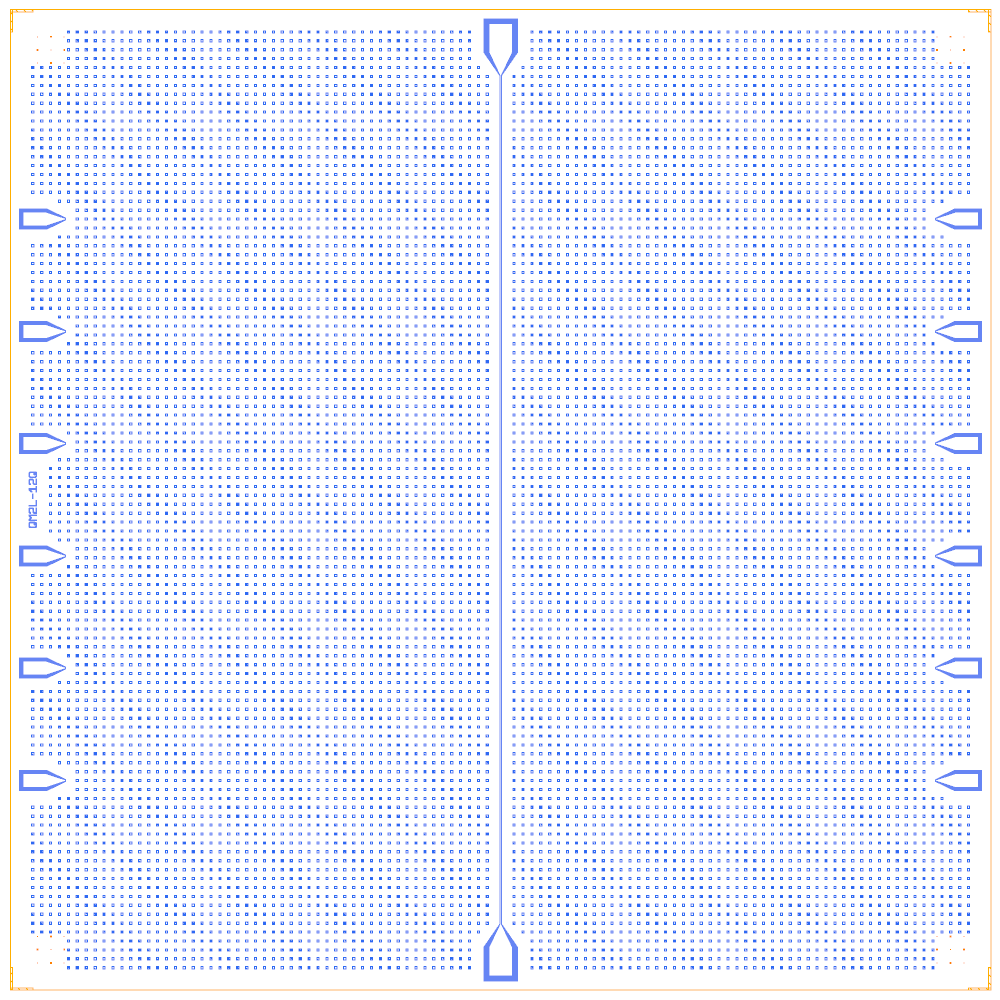

**On the chip so far:** 14 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_s3_feedline.png')

In [7]:
fl = d.route("FL", top.a, bot.a, a=11.7, b=5.1, r=70)
rebuild(d)
print(f"FL: {fl.length:.1f} µm")
layout_step(d, OUT / "qm2litho_12q_flux_processor_s3_feedline.png", size=(1000, 1000), width=360)

## Design 4 · Qubit placement: twelve flux-tunable Xmons with trilayer SQUIDs

**The junction.** The source gives L_J = 15.904 nH for every qubit; its qubits are flux-tunable, so the junction is a
SQUID (the LOM model of `TransmonCrossFL` treats it as one, with the flux line as a flux-bias control).
`trilayer_junction(cell, lj_nH=15.904, squid=True)` draws a Quantcore trilayer SQUID (two junctions in a loop, fingers
on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) whose total L_J at zero flux is 15.9 nH, and returns the values
the LOM uses. The PDK window judges the device, the SQUID's two junctions in parallel: drawn on the PDK finger grid the 15.9 nH comes
out as 15.31 nH, so its R_n is 102 kΩ (each junction 205 kΩ), **outside the PDK window of 40–50 kΩ**. Following the project rule (values are flagged, never
retuned), the source's L_J stays and the DRC reports the design warning `pdk_rn`.

In [8]:
LJ_NH = 15.903982                                # the source's Lj (zero-flux SQUID inductance)
JJP, JJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=LJ_NH, squid=True)
print("cell parameters:", JJP)
print("LOM SQUID:      ", JJ, f"→ device R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (each junction "
      f"{rn_from_lj(2 * JJ['Lj_nH']) / 1e3:.0f} kΩ; PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 15.903982}}
LOM SQUID:       {'Lj_nH': 15.3055, 'Cj_fF': 6.6} → device R_n 102.3 kΩ (each junction 205 kΩ; PDK window 40–50 kΩ)


**The qubits.** Metal `TransmonCrossFL`: cross 260 µm arms, 35 µm wide, 20 µm gap; a flux T-line at the bottom arm
(`t_top` 24 µm, 4 µm inductive gap, 5/3 µm); one claw (190 × 10 µm, 6 µm gap, 5 µm ground spacing, no claw CPW) on the
arm facing the line. The west column is rotated −90° and the east column +90°, so every claw faces the feedline and
every flux line faces its side pad. `q.c` is the claw pin, `q.flux_line` the flux pin.

<metal:TransmonCrossFL Q01_L ports=['c', 'flux_line', 'squid_a', 'squid_b']>


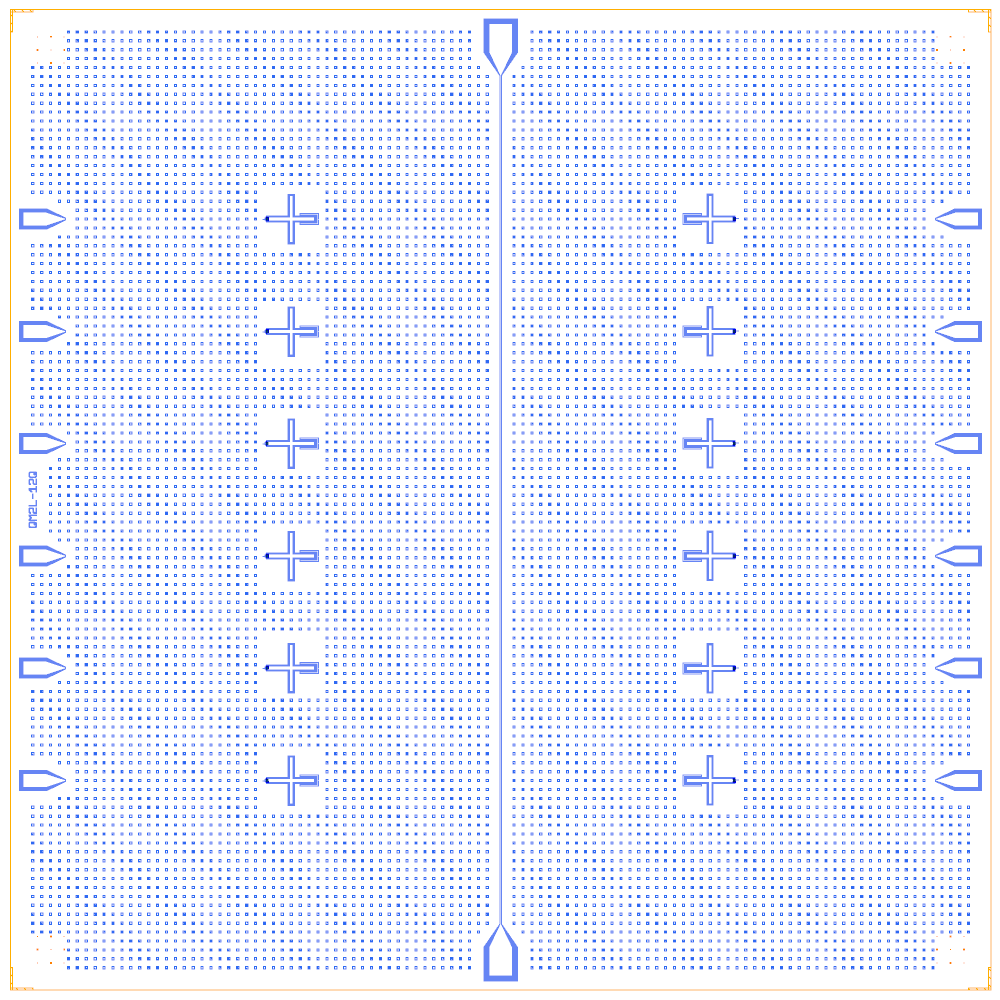

**On the chip so far:** 14 pads · 12 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 12 component(s) `Q01_L`, `Q01_R`, `Q02_L`, `Q02_R`, `Q03_L`, `Q03_R`, `Q04_L`, `Q04_R` … (+4).

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_components.png')

In [9]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_gap=6, claw_width=10,
            claw_cpw_length=0, claw_cpw_width=10, ground_spacing=5)
XMON_FL = dict(cross_length=260, cross_width=35, cross_gap=20, make_fl=True,
               fl_options={"t_top": 24, "t_offset": 0, "t_inductive_gap": 4, "t_width": 5, "t_gap": 3},
               connection_pads={"c": CLAW})
qubits = {}
with d.batch():
    for name, x, y in SITES:
        qubits[name] = d.add(name, "metal:TransmonCrossFL", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90,
                             junction=JJ, **XMON_FL, **JJP)
print(qubits["Q01_L"])
layout_step(d, OUT / "qm2litho_12q_flux_processor_components.png", size=(1000, 1000), width=360)

## Design 5 · Readout: twelve λ/4 hanger readouts

**Readouts.** Each readout is one qcc route: claw → meander → a 260 µm section along the feedline with a 7 µm ground
strip → short to ground.
- `fl.hanger(near=(x, y), length=260, side=..., ground_gap=7, end="short")` centres the coupled section at the
  feedline point nearest (x, y), here 130 µm below the qubit's row. Placing it by position, not by arclength from the
  launch pad, keeps it at its qubit when the pad moves.
- `meander=L_k` is the source's L_k = v / (4 f_k) (the coupled section included), 5 meanders, 85 µm bends: the
  router draws the length the path leaves over as one KQC `Meander` with the 5 turns asked for (fewer, with a
  warning, only if 5 would be narrower than the bend radius).
- The frequency plan runs in site order: Q01_L 6.05, Q01_R 6.12, Q02_L 6.19 GHz, … Q06_R 6.82 GHz.

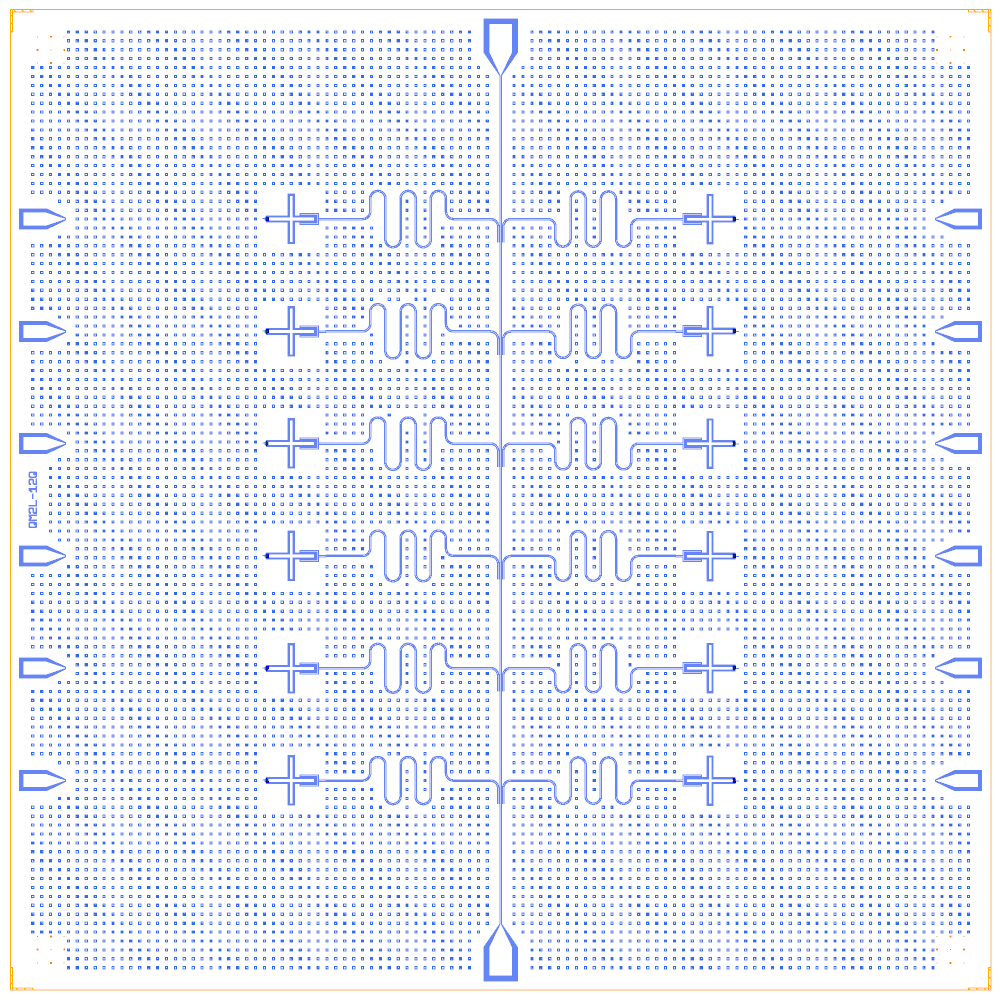

**On the chip so far:** 14 pads · 12 qubits · 0 other components · 13 routes · 0 declared couplings. **This step added** 12 route(s) `R_Q01_L`, `R_Q01_R`, `R_Q02_L`, `R_Q02_R`, `R_Q03_L`, `R_Q03_R`, `R_Q04_L`, `R_Q04_R` … (+4).

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_s5_readouts.png')

In [10]:
F_GHZ = [6.05 + 0.07 * k for k in range(12)]     # site order Q01_L, Q01_R, Q02_L, ...
with d.batch():
    for (name, x, y), f in zip(SITES, F_GHZ):
        left = x < 0
        L = 1.20e8 / (4 * f * 1e9) * 1e6         # source L_k = v / (4 f_k), µm
        hg = fl.hanger(near=(X0, Y0 + y - 130), length=260, side="right" if left else "left", ground_gap=7,
                       direction="forward", end="short")
        d.route(f"R_{name}", qubits[name].c, hg, meander=round(L, 1), r=85).set(meanders=5)
layout_step(d, OUT / "qm2litho_12q_flux_processor_s5_readouts.png", size=(1000, 1000), width=360)

## Design 6 · Coupling: none

There are no qubit–qubit couplers: the source is a readout and flux test processor, so each qubit sees only its own
readout and its flux line. Nothing is placed here.

## Design 7 · Routing: the twelve flux lines

**Flux lines.** `FLX_<q>` runs from the qubit's flux pin to its side pad at 6/8 µm with 55 µm bends. The LOM reads a
line that ends on a flux pin as a flux-bias control, not as a resonator. The side pads were placed in Design 2 at
each qubit's row, so each line runs out to the die edge at its qubit's height.

{'FL': 9520.0, 'R_Q01_L': 4958.7, 'R_Q01_R': 4902.0, 'FLX_Q01_L': 2208.5, 'FLX_Q01_R': 2208.5, 'FLX_Q02_L': 2208.5, 'FLX_Q02_R': 2208.5, 'FLX_Q03_L': 2208.5, 'FLX_Q03_R': 2208.5, 'FLX_Q04_L': 2208.5, 'FLX_Q04_R': 2208.5, 'FLX_Q05_L': 2208.5, 'FLX_Q05_R': 2208.5, 'FLX_Q06_L': 2208.5, 'FLX_Q06_R': 2208.5}


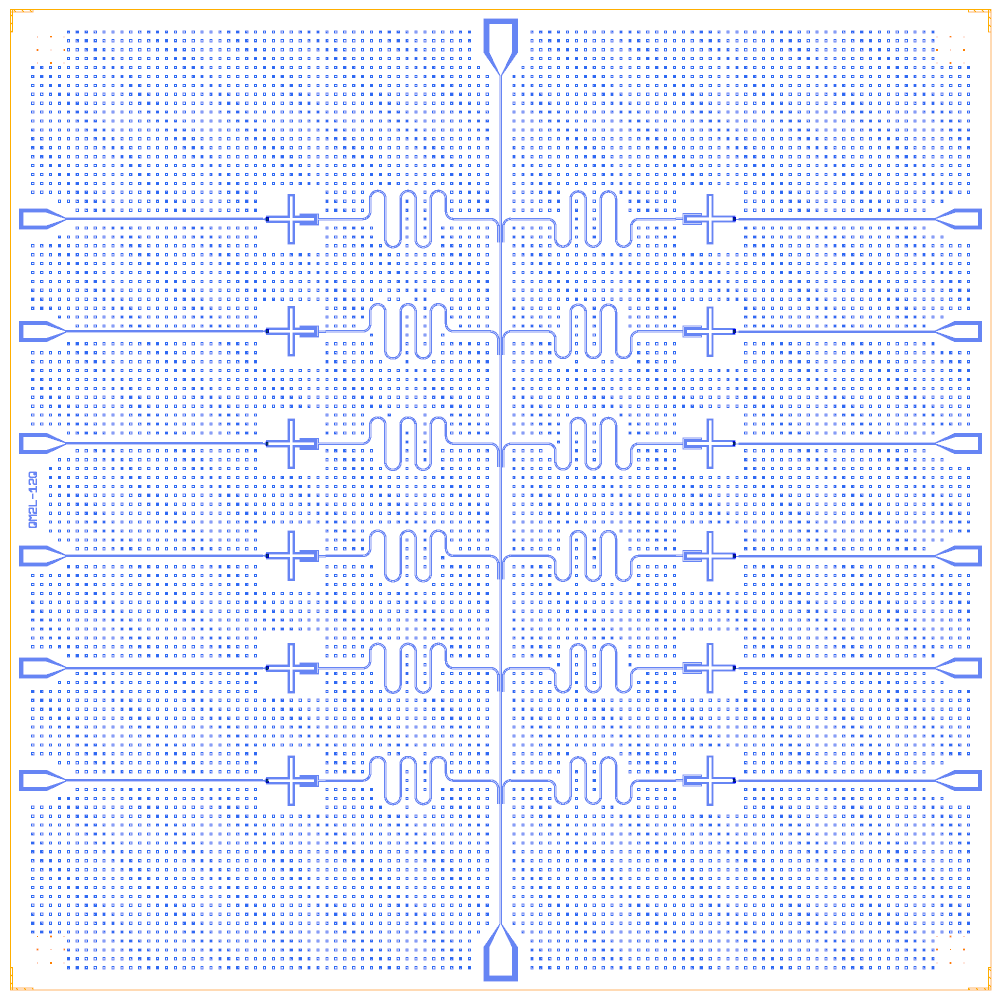

**On the chip so far:** 14 pads · 12 qubits · 0 other components · 25 routes · 0 declared couplings. **This step added** 12 route(s) `FLX_Q01_L`, `FLX_Q01_R`, `FLX_Q02_L`, `FLX_Q02_R`, `FLX_Q03_L`, `FLX_Q03_R`, `FLX_Q04_L`, `FLX_Q04_R` … (+4).

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_s7_flux.png')

In [11]:
with d.batch():
    for name, x, y in SITES:
        d.route(f"FLX_{name}", qubits[name].flux_line, d[f"F_{name}"].a, a=6, b=8, r=55)
rebuild(d)
lengths = d.result.route_lengths()
print({k: round(v, 1) for k, v in lengths.items() if k.startswith(("FL", "R_Q01", "FLX_Q01"))})
layout_step(d, OUT / "qm2litho_12q_flux_processor_s7_flux.png", size=(1000, 1000), width=360)

## Design 8 · The whole chip: targets, sim groups, centring, save

**Targets and sim groups:** each readout's target is the source's plan (`F_GHZ`, 6.05 … 6.82 GHz); one sim group per
qubit with its readout, the feedline and its flux line (the default analyses: eigenmode / EPR and Q3D C-matrix).

**Centring.** The source chip is symmetric about its centre and the rebuild keeps the source coordinates, so the content is already
centred: `center_in_die(d)` measures the bounding box of every instance and route and returns (0, 0) when it is
within 50 µm of the die centre (it would shift everything otherwise).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the twelve readouts were added before the twelve flux lines here; the v1 added them pairwise), so `git diff` stays empty.

shift applied (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/community/qm2litho_12q_flux_processor.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer qm2litho_12q_flux_processor: 26 instances, 25 routes, live=False> → examples\designs\community\qm2litho_12q_flux_processor.json


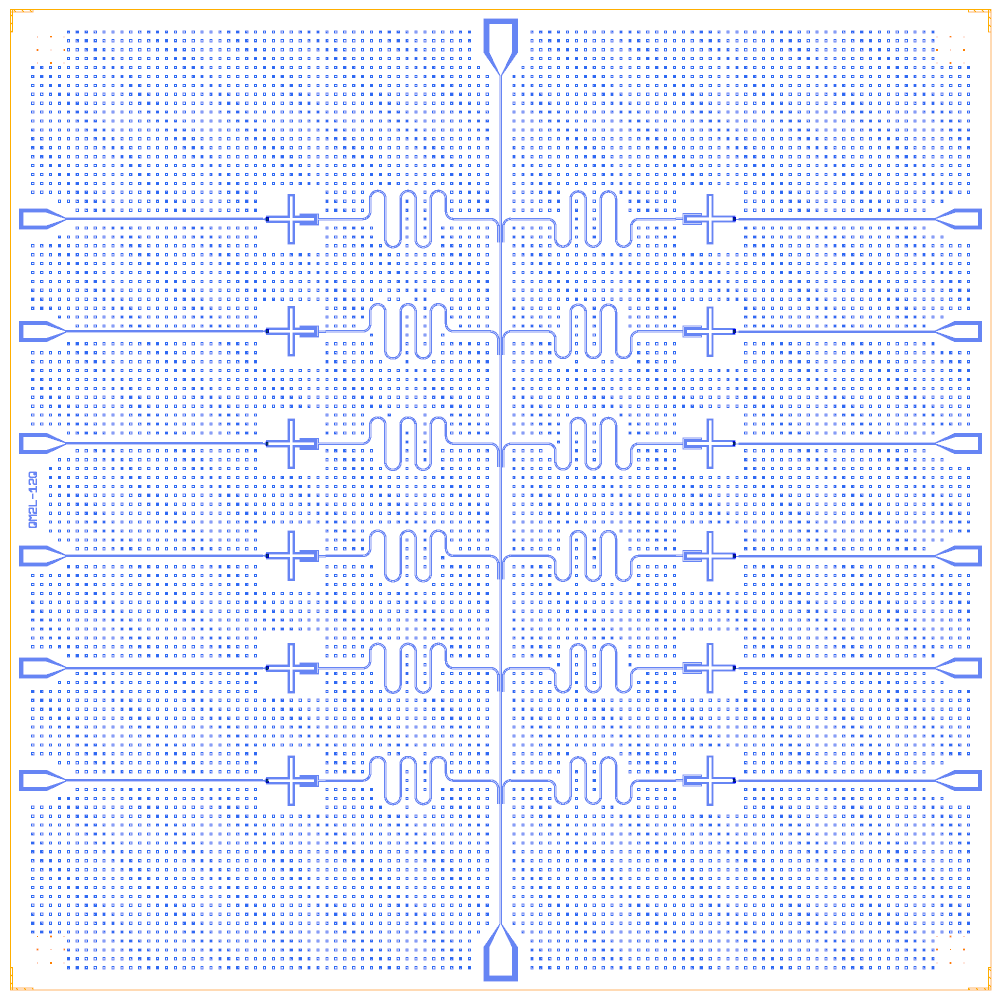

**On the chip so far:** 14 pads · 12 qubits · 0 other components · 25 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/qm2litho_12q_flux_processor_routes.png')

In [12]:
for (name, x, y), f in zip(SITES, F_GHZ):
    d.targets(**{f"R_{name}": {"f_GHz": round(f, 3)}})
    d.sim_group(name, [name, f"R_{name}", "FL", f"FLX_{name}"])
print("shift applied (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "qm2litho_12q_flux_processor.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "qm2litho_12q_flux_processor_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the SQUID attachment points (`squid_a` / `squid_b`; the
  cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on all twelve SQUIDs (device R_n 102.3 kΩ at the source's
  15.9 nH).

Expected (from the v1 run): **no errors**; 24 `dangling_port` warnings, the twelve SQUIDs' `squid_a` / `squid_b`; 12 `pdk_rn`.
No `pad_edge`: the 14 pads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit. Each `TransmonCrossFL` is a grounded island with its SQUID to ground,
a claw node and a flux-bias control (`FLX_<q>`). Each readout is a λ/4 `TLres` from the claw node with a `HANGER` (κ)
to the feedline node `FL`, which carries the two 50 Ω launch-pad ports. The flux pads are not circuit nodes: the flux
lines are controls.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation (per qubit / readout pair, with the feedline)

Each qubit is simulated with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values), at zero
flux. Targets in brackets are the source's readout plan. The source states no qubit frequency.

What the table shows (from the v1 run):
- every qubit at **3.258 GHz** (α −150 MHz) with the drawn 15.31 nH SQUID: below the PDK band of 4–8 GHz (no qubit
  target is set, so the DRC has no `pdk_fq` warning to give);
- the readouts at **5.742 … 6.399 GHz** in 60 MHz steps, 5–6 % below the source's plan (6.05 … 6.82 GHz): the source's
  L = v/(4f) takes v = 1.2 × 10⁸ m/s, the PDK CPW on sapphire (with the Nb kinetic inductance) is slower and the claw
  loads the open end. Flagged, not retuned (the source's lengths are kept);
- κ 0.066–0.090 MHz through the 260 µm hangers; χ −0.10 … −0.12 MHz, small because the qubits sit 2.5–3.1 GHz below
  their readouts.

In [ ]:
groups = {n: [n, f"R_{n}", "FL"] for n, _, _ in SITES}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, d.data["targets"])))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values; red bars the readout plan), (b) the dispersive shift |χ| of
each readout. From the v1 run the plot shows LOM 1's two offsets: the qubits near 3.26 GHz, far below their readouts,
and every readout 5–6 % below its red target.

In [ ]:
plot_lom(res, OUT / "qm2litho_12q_flux_processor_lom.png", targets=d.data["targets"],
         title="qm2litho_12q_flux_processor: LOM per qubit + readout")

## LOM 3 · One geometry change, by hand: a flux bias

Before the FEM, a design step by hand. The flux line tunes the SQUID: at a flux Φ through its loop the effective inductance is L_J(Φ) = L_J(0) / |cos(πΦ/Φ0)|
(symmetric SQUID). The `junction` values of an instance are what the simulation uses (the drawn SQUID does not change),
so a flux bias of 0.25 Φ0 on Q01_L is L_J × √2 in a copy: f_q drops by 17 % (3.258 → 2.716 GHz in the v1 run), the
qubit moves away from its readout and |χ| shrinks (0.120 → 0.082 MHz); the readout stays at 5.742 GHz. `design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
PHI = 0.25                                       # flux bias in units of Φ0
d2["Q01_L"].set(junction={"Lj_nH": round(JJ["Lj_nH"] / abs(math.cos(math.pi * PHI)), 4), "Cj_fF": JJ["Cj_fF"]})
print("Q01_L L_J at Φ = 0.25 Φ0:", d2["Q01_L"].spec["junction"])
res2 = simulate_groups(d2, {"Q01_L": groups["Q01_L"]})
display(Markdown(params_delta_md({"Q01_L": res["Q01_L"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Every qubit's sim group (qubit, readout, feedline, flux line) is exported as a Q3D C-matrix job (capacitances by net
name) and an eigenmode/EPR job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`. Exporting again
replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
sites = [n for n, _, _ in SITES]
jobs = export_sims(DESIGN, sites, analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, sites, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of each qubit's group: the cross island, its claw, the readout, the feedline and the flux line the box
cuts, as named nets (`Q01_L.island`, `Q01_L.c`, …). Each net is named after its LOM node, so the matrix goes straight
into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that
there are none (twelve jobs, one after the other: with `RUN_FEM = True` this is the long cell, ≈ 1–5 min per job).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same twelve boxes in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet (at zero flux) and the lines the box
cuts end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`)
turns the junction's energy participation p_J into dressed frequencies, α and χ. Twelve eigenmode solves take a while
(minutes each); `RUN_FEM = {"q3d_cmatrix"}` solves only the Q3D jobs.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q01_L`: its readout is a hanger on the feedline, so S21 between the two
feedline ends the box cuts shows the notch (f_r and the external κ).

In [ ]:
f_r0 = res["Q01_L"].params.get("R_Q01_L.f_GHz")        # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q01_L", jobs_eig["Q01_L"][0], keep_eig["Q01_L"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q01_L"]:
    display(Markdown(driven_md(keep_drv["Q01_L"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {n: (n, f"R_{n}", n) for n in sites}     # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "qm2litho_12q_flux_processor_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q01_L"]:
    qb, rr, _ = PAIRS["Q01_L"]
    fem_values.setdefault("Q01_L", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q01_L"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of Q01_L's readout.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the readout plan (one sim group)

The design carries the source's readout plan as its targets (Design 8: 6.05 … 6.82 GHz); it sets no qubit target.
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/qm2litho_12q_flux_processor_target.json`,
and the feedback works on that copy. **One sim group:** `loop.analyse(..., group="Q01_L")` builds the circuit of the
`Q01_L` sim group only (the qubit, its readout, the feedline, its flux line) and runs the estimators (QuCat, SQcircuit,
scqubits, Metal LOM) on that pair, so the step takes a minute or two instead of twelve times that; the other eleven
readouts follow the same knob (drop `group=` to run all twelve pairs). Kept FEM results fill the circuit: the group's
Q3D C-matrix and its own eigenmode job (pyEPR joins the estimators, the mode Q gives the hanger's κ); without them, the
LOM estimates. From the v1 run R_Q01_L sits at 5.742 GHz against 6.05 GHz (5 % low), so `loop.feedback` shortens its
meander by about that much (the claw-to-feedline path is far shorter), proposes revision 1, builds and netlist-checks
it.

**No PDK L_J bounds:** no qubit target is set, so L_J is not a knob to move, and the source's 15.9 nH SQUIDs sit far
outside the 40–50 kΩ window (`pdk_rn`, flagged, not retuned), where `pdk_lj_bounds` would pull them.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

GROUP = "Q01_L"                                  # one sim group (12 pairs at once take much longer)
DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the readout plan), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the SQUIDs are outside the window
FILL = [k for k in (keep_q3d.get(GROUP), keep_eig.get(GROUP)) if k] or None   # the group's kept Q3D + EPR
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False, group=GROUP)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated on the same sim group: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/qm2litho_12q_flux_processor/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the group's Q3D and eigenmode jobs are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D and eigenmode jobs of the group, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {**export_sims(rev, [GROUP], root=f"build/jobs/rev{k}"),
              **{f"{GROUP} · eig": job for job in export_sims(rev, [GROUP], analysis="eigenmode_epr",
                                                           root=f"build/jobs/rev{k}").values()}}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0, group=GROUP)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "qm2litho_12q_flux_processor_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/qm2litho_12q_flux_processor.json` (Design 8);
  `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the build
  drew (Metal's rule, the original's: `cheese source: build`, no PDK band added; `qcc mask` keeps it too). The table lists each fab layer
  (9210 holes in the v1 run).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/qm2litho_12q_flux_processor.json`,
  `qcc design drc …`, `qcc mask …` (the fab file), `qcc sim build … -g Q01_L -a q3d_cmatrix`,
  `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full chip; qubit Q01_L with its claw, flux line and readout; its trilayer SQUID and flux T-line; the two facing
couplers of row 1 on the feedline; the west flux pad of row 1, 100 µm from the die edge; and the fab mask round Q01_L (1/0 etch with Metal's cheese,
the 3/0 keep-out with the holes on it too, the junction layers).

In [ ]:
snap(d, OUT / "qm2litho_12q_flux_processor.png", size=(1600, 1600))
qx, qy = X0 - 2350, Y0 + 3150
snap(d, OUT / "qm2litho_12q_flux_processor_q01l.png", box=(qx - 500, qy - 400, qx + 500, qy + 400), size=(1250, 1000), width=450)
snap(d, OUT / "qm2litho_12q_flux_processor_jj.png", box=(qx - 305, qy - 25, qx - 255, qy + 25), width=300)
snap(d, OUT / "qm2litho_12q_flux_processor_couplers.png", box=(X0 - 150, qy - 300, X0 + 150, qy + 50), size=(900, 1050), width=340)
snap(d, OUT / "qm2litho_12q_flux_processor_fluxpad.png", box=(0, qy - 400, 800, qy + 400), size=(800, 800), width=300)
snap_file(Path("build") / "qm2litho_12q_flux_processor_fab.oas", OUT / "qm2litho_12q_flux_processor_cheese.png",
          box=(qx - 600, qy - 500, X0 + 100, qy + 500), size=(1200, 1100), width=420);

## Summary

- **Matches the source:** the qubit cell and its options, the positions, the feedline CPW, the readout plan and
  lengths, the hanger couplers (the spec's reading of the 18 µm gap), the flux lines, the source's L_J, and Metal's GDS
  cheese (25 µm / 100 µm, 25 µm buffer), drawn by the build and kept in the mask (9210 holes in the v1 run).
- **Changed by the PDK:** the PDK frame on the 11 × 11 mm die, sapphire, drawn trilayer SQUIDs (15.31 nH on the finger
  grid), the launch and flux pads 100 µm from the die edge (the feedline and the flux lines are longer), content centred
  (no shift needed).
- **Open PDK design warnings:** `pdk_rn` on all twelve SQUIDs (device R_n 102 kΩ at the source's 15.9 nH; flagged, not
  retuned). The qubits sit at 3.26 GHz (from the v1 run), below the PDK band (no target, so no `pdk_fq`); the readouts 5–6 % below the
  source's plan (from the v1 run).
- **Layout:** built in segments (die, pads, the feedline, the Xmons, the readouts, the flux lines, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the design's own readout plan on a copy, one sim group (`Q01_L`) at a time: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.